In [ ]:
!pip install -q kagglehub albumentations

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import cv2
from tqdm.auto import tqdm
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.mixed_precision import set_global_policy

import albumentations as A
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

# Enable mixed precision
set_global_policy('mixed_float16')

# Set random seeds
def set_seed(seed=42):
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

set_seed(42)

# GPU Configuration
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"✓ Found {len(gpus)} GPU(s)")
        print(f"GPU: {gpus[0].name}")
    except RuntimeError as e:
        print(e)
else:
    print("No GPU found, using CPU")

print(f"\nTensorFlow version: {tf.__version__}")
print(f"Keras version: {keras.__version__}")
print(f"Mixed precision: {tf.keras.mixed_precision.global_policy().name}")

✓ Found 1 GPU(s)
GPU: /physical_device:GPU:0

TensorFlow version: 2.19.0
Keras version: 3.10.0
Mixed precision: mixed_float16


In [ ]:
import kagglehub

# Download dataset
dataset_path = kagglehub.dataset_download('adham7elmy/faceforencispp-extracted-frames')
print('Data source import complete.')
print(f"Dataset path: {dataset_path}")

# Navigate to the correct directory
base_path = Path(dataset_path)
print(f"\nDataset structure:")
for item in list(base_path.rglob("*"))[:10]:  # Show first 10 items
    if item.is_dir():
        print(f"  {item.relative_to(base_path)}/")

100%|██████████| 13.4G/13.4G [10:35<00:00, 22.7MB/s]

Extracting files...


Data source import complete.
Dataset path: /root/.cache/kagglehub/datasets/adham7elmy/faceforencispp-extracted-frames/versions/4

Dataset structure:
  real/
  fake/
  real/175/
  real/548/
  real/733/
  real/756/
  real/217/
  real/266/
  real/082/
  real/605/


In [ ]:
print("="*80)
print("📁 LOADING DATASET")
print("="*80)

# Find all image files
image_extensions = {'.jpg', '.jpeg', '.png'}
image_files = []

for ext in image_extensions:
    image_files.extend(list(base_path.rglob(f"*{ext}")))

print(f"Total images found: {len(image_files):,}")

# Create DataFrame
data_records = []

for img_path in tqdm(image_files, desc="Processing paths"):
    parts = img_path.parts

    # Find category in path
    category = None
    for part in parts:
        part_lower = part.lower()
        if 'faceswap' in part_lower:
            category = 'FaceSwap'
        elif 'real' in part_lower:
            category = 'real'
        elif 'face2face' in part_lower:
            category = 'Face2Face'
        elif 'neuraltextures' in part_lower or 'neural' in part_lower:
            category = 'NeuralTextures'
        elif 'faceshifter' in part_lower:
            category = 'FaceShifter'
        elif 'deepfakes' in part_lower or 'deepfake' in part_lower:
            category = 'Deepfakes'

        if category:
            break

    if category:
        data_records.append({
            'path': str(img_path),
            'category': category,
            'filename': img_path.name
        })

df = pd.DataFrame(data_records)

print(f"\n✅ DataFrame created with {len(df):,} images")
print(f"\nCategory distribution:")
print(df['category'].value_counts().sort_index())

📁 LOADING DATASET
Total images found: 191,550


Processing paths:   0%|          | 0/191550 [00:00<?, ?it/s]


✅ DataFrame created with 191,550 images

Category distribution:
category
Deepfakes         31843
Face2Face         31949
FaceShifter       31924
FaceSwap          31954
NeuralTextures    31931
real              31949
Name: count, dtype: int64


In [ ]:
print("\n" + "="*80)
print("⚖️  DATASET BALANCING & PREPARATION (6 CLASSES)")
print("="*80)

# Create label mapping
category_mapping = {
    'FaceSwap': 0,
    'real': 1,
    'Face2Face': 2,
    'NeuralTextures': 3,
    'FaceShifter': 4,
    'Deepfakes': 5
}

df['label'] = df['category'].map(category_mapping)
df['category_label'] = df['label']

# Remove unmapped
if df['label'].isna().any():
    print(f"⚠️  Removing {df['label'].isna().sum()} unmapped entries")
    df = df.dropna(subset=['label'])

df['label'] = df['label'].astype(int)

# Balance dataset
MAX_SAMPLES_PER_CLASS = 1000
NUM_CLASSES = 6

print(f"\nOriginal distribution:")
print(df['category'].value_counts())

target_count = min(df['label'].value_counts().min(), MAX_SAMPLES_PER_CLASS)
print(f"\nTarget samples per class: {target_count:,}")

balanced_dfs = []
for label in range(NUM_CLASSES):
    class_df = df[df['label'] == label]

    if len(class_df) >= target_count:
        balanced_dfs.append(class_df.sample(n=target_count, random_state=42))
    elif len(class_df) > 0:
        balanced_dfs.append(class_df)
        print(f"⚠️  Class {label} only has {len(class_df)} samples")

df = pd.concat(balanced_dfs).reset_index(drop=True)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print(f"\n✅ Balanced dataset:")
print(df['category'].value_counts().sort_index())
print(f"Total: {len(df):,} images")

# Clean up
import gc
del balanced_dfs
gc.collect()


⚖️  DATASET BALANCING & PREPARATION (6 CLASSES)

Original distribution:
category
FaceSwap          31954
real              31949
Face2Face         31949
NeuralTextures    31931
FaceShifter       31924
Deepfakes         31843
Name: count, dtype: int64

Target samples per class: 1,000

✅ Balanced dataset:
category
Deepfakes         1000
Face2Face         1000
FaceShifter       1000
FaceSwap          1000
NeuralTextures    1000
real              1000
Name: count, dtype: int64
Total: 6,000 images


19

In [ ]:
print("\n" + "="*80)
print("✂️  CREATING TRAIN/VAL/TEST SPLITS")
print("="*80)

# Split: 80% train, 10% val, 10% test
train_val_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df['label']
)

train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.2,
    random_state=42,
    stratify=train_val_df['label']
)

def print_split_stats(df_split, name):
    print(f"\n{name}: {len(df_split):,} samples")
    counts = df_split['category'].value_counts().sort_index()
    for cat, count in counts.items():
        print(f"  {cat:15s}: {count:,} ({count/len(df_split)*100:.1f}%)")

print_split_stats(train_df, "Train")
print_split_stats(val_df, "Validation")
print_split_stats(test_df, "Test")

print(f"\n✅ Split ratios: Train={len(train_df)/len(df)*100:.1f}%, Val={len(val_df)/len(df)*100:.1f}%, Test={len(test_df)/len(df)*100:.1f}%")


✂️  CREATING TRAIN/VAL/TEST SPLITS

Train: 3,840 samples
  Deepfakes      : 640 (16.7%)
  Face2Face      : 640 (16.7%)
  FaceShifter    : 640 (16.7%)
  FaceSwap       : 640 (16.7%)
  NeuralTextures : 640 (16.7%)
  real           : 640 (16.7%)

Validation: 960 samples
  Deepfakes      : 160 (16.7%)
  Face2Face      : 160 (16.7%)
  FaceShifter    : 160 (16.7%)
  FaceSwap       : 160 (16.7%)
  NeuralTextures : 160 (16.7%)
  real           : 160 (16.7%)

Test: 1,200 samples
  Deepfakes      : 200 (16.7%)
  Face2Face      : 200 (16.7%)
  FaceShifter    : 200 (16.7%)
  FaceSwap       : 200 (16.7%)
  NeuralTextures : 200 (16.7%)
  real           : 200 (16.7%)

✅ Split ratios: Train=64.0%, Val=16.0%, Test=20.0%



👤 FACE EXTRACTION SETUP
✅ Face detector loaded

🧪 Testing face extraction...


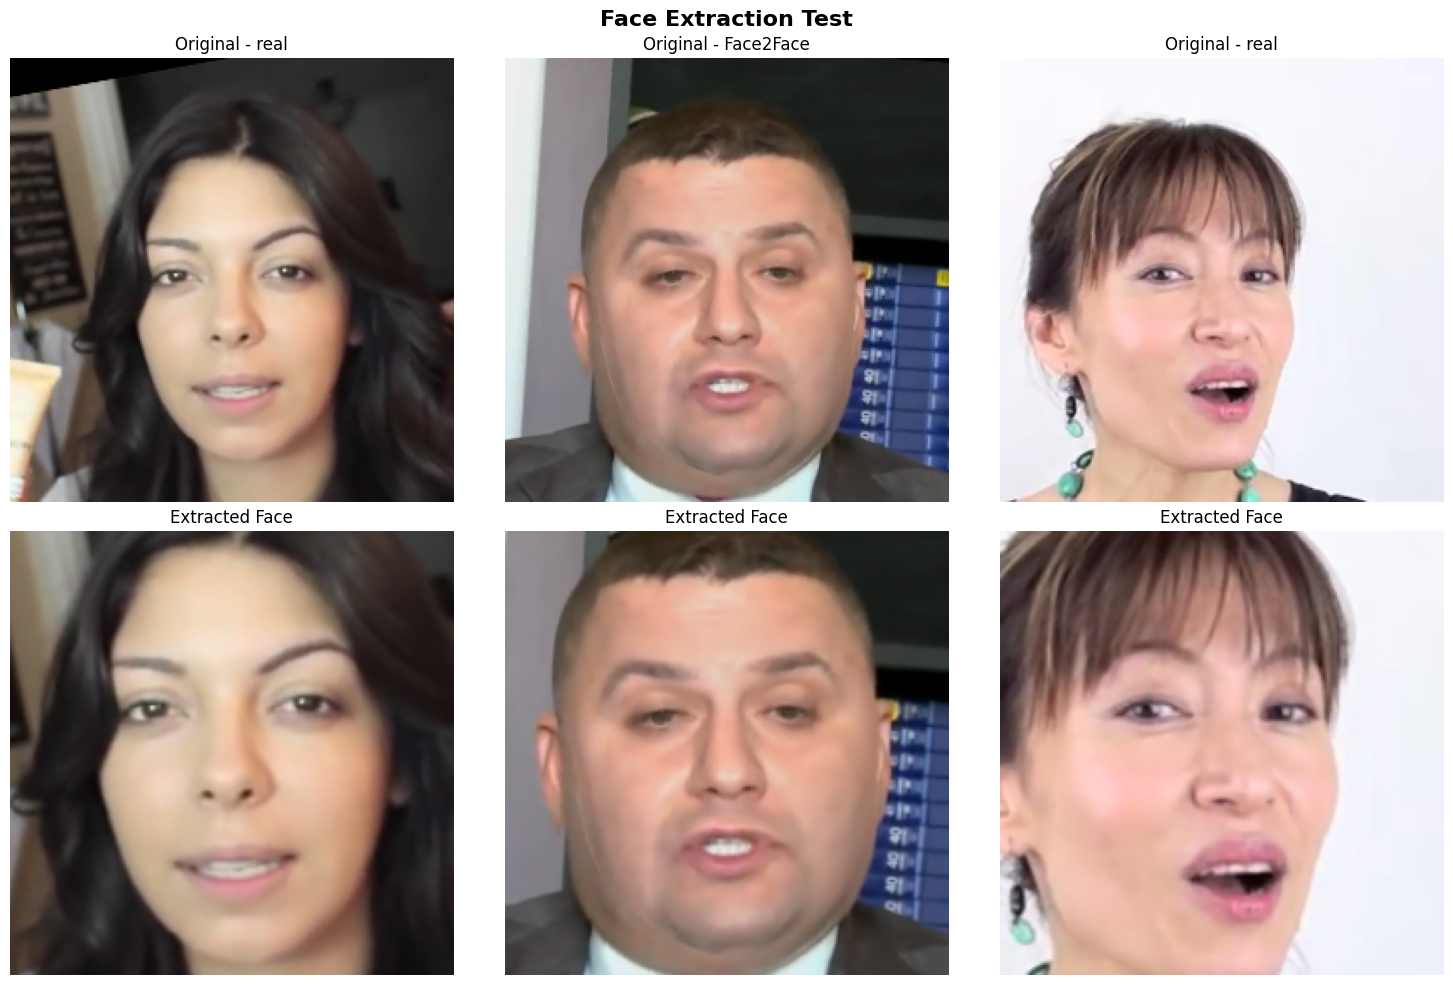

✅ Face extraction ready!


In [ ]:
print("\n" + "="*80)
print("👤 FACE EXTRACTION SETUP")
print("="*80)

class FaceExtractor:
    """Extract faces using OpenCV Haar Cascades"""

    def __init__(self):
        self.face_cascade = cv2.CascadeClassifier(
            cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
        )
        print("✅ Face detector loaded")

    def extract_face(self, image_path, target_size=(224, 224), margin=20):
        """Extract and resize face from image"""
        try:
            image = cv2.imread(image_path)
            if image is None:
                return None

            image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

            faces = self.face_cascade.detectMultiScale(
                gray,
                scaleFactor=1.1,
                minNeighbors=5,
                minSize=(30, 30)
            )

            if len(faces) == 0:
                return cv2.resize(image_rgb, target_size)

            largest_face = max(faces, key=lambda rect: rect[2] * rect[3])
            x, y, w, h = largest_face

            x1 = max(0, x - margin)
            y1 = max(0, y - margin)
            x2 = min(image_rgb.shape[1], x + w + margin)
            y2 = min(image_rgb.shape[0], y + h + margin)

            face_img = image_rgb[y1:y2, x1:x2]
            return cv2.resize(face_img, target_size)

        except Exception:
            return None

# Initialize
face_extractor = FaceExtractor()

# Test
print("\n🧪 Testing face extraction...")
sample_imgs = train_df.sample(3)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for idx, (_, row) in enumerate(sample_imgs.iterrows()):
    orig = cv2.imread(row['path'])
    if orig is not None:
        orig = cv2.cvtColor(orig, cv2.COLOR_BGR2RGB)
        axes[0, idx].imshow(orig)
        axes[0, idx].set_title(f"Original - {row['category']}")
        axes[0, idx].axis('off')

    face = face_extractor.extract_face(row['path'])
    if face is not None:
        axes[1, idx].imshow(face)
        axes[1, idx].set_title(f"Extracted Face")
        axes[1, idx].axis('off')

plt.suptitle("Face Extraction Test", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

print("✅ Face extraction ready!")

In [ ]:
print("\n" + "="*80)
print("🔄 DATA AUGMENTATION SETUP")
print("="*80)

# Training augmentation
train_transform = A.Compose([
    A.Resize(224, 224),
    A.HorizontalFlip(p=0.5),

])

# Validation augmentation
val_transform = A.Compose([
    A.Resize(224, 224),
])

print("✅ Augmentation pipelines created")


🔄 DATA AUGMENTATION SETUP
✅ Augmentation pipelines created


In [ ]:
print("\n" + "="*80)
print("🔧 FIXED TENSORFLOW DATA GENERATOR")
print("="*80)

class FixedDeepfakeGenerator(keras.utils.Sequence):
    """Fixed TensorFlow generator matching PyTorch preprocessing exactly"""

    def __init__(self, df, face_extractor, augmentation=None,
                 batch_size=64, shuffle=True, use_face_extraction=True):
        self.df = df.reset_index(drop=True)
        self.face_extractor = face_extractor
        self.augmentation = augmentation
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.use_face_extraction = use_face_extraction
        self.indices = np.arange(len(self.df))

        if self.shuffle:
            np.random.shuffle(self.indices)

    def __len__(self):
        return int(np.floor(len(self.df) / self.batch_size))  # Drop incomplete batches

    def __getitem__(self, idx):
        batch_indices = self.indices[idx * self.batch_size:(idx + 1) * self.batch_size]

        batch_images = []
        batch_labels = []

        for i in batch_indices:
            row = self.df.iloc[i]

            # Load image
            if self.use_face_extraction:
                image = self.face_extractor.extract_face(row['path'])
            else:
                image = cv2.imread(row['path'])
                if image is not None:
                    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
                    image = cv2.resize(image, (224, 224))

            if image is None:
                image = np.zeros((224, 224, 3), dtype=np.uint8)

            # Ensure uint8
            image = image.astype(np.uint8)

            # Apply augmentation (Albumentations)
            if self.augmentation is not None:
                augmented = self.augmentation(image=image)
                image = augmented['image']

            # ✅ CRITICAL FIX: Keep in [0, 255] range, convert to float32
            # EfficientNet preprocessing will be applied in model
            image = image.astype(np.float32)

            batch_images.append(image)
            batch_labels.append(int(row['label']))

        return np.array(batch_images, dtype=np.float32), np.array(batch_labels, dtype=np.int32)

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

# Configuration - MATCH PYTORCH EXACTLY
CONFIG = {
    'batch_size': 64,  # Same as PyTorch
    'use_face_extraction': True
}

print(f"Creating FIXED TensorFlow generators...")
print(f"  Batch size: {CONFIG['batch_size']}")

# Create generators
train_generator = FixedDeepfakeGenerator(
    train_df,
    face_extractor,
    augmentation=train_transform,
    batch_size=CONFIG['batch_size'],
    shuffle=True,
    use_face_extraction=CONFIG['use_face_extraction']
)

val_generator = FixedDeepfakeGenerator(
    val_df,
    face_extractor,
    augmentation=val_transform,
    batch_size=CONFIG['batch_size'],
    shuffle=False,
    use_face_extraction=CONFIG['use_face_extraction']
)

test_generator = FixedDeepfakeGenerator(
    test_df,
    face_extractor,
    augmentation=val_transform,
    batch_size=CONFIG['batch_size'],
    shuffle=False,
    use_face_extraction=CONFIG['use_face_extraction']
)

print(f"\n✅ FIXED Generators created:")
print(f"  Train: {len(train_df):,} samples ({len(train_generator)} batches)")
print(f"  Val:   {len(val_df):,} samples ({len(val_generator)} batches)")
print(f"  Test:  {len(test_df):,} samples ({len(test_generator)} batches)")

# Verify
print("\n🔍 Verifying FIXED data loading...")
X_batch, y_batch = train_generator[0]
print(f"  Batch shape: {X_batch.shape}")
print(f"  Labels shape: {y_batch.shape}")
print(f"  Image range: [{X_batch.min():.1f}, {X_batch.max():.1f}]")
print(f"  Labels: {np.unique(y_batch)}")

if X_batch.min() >= 0 and X_batch.max() <= 255:
    print("\n✅ Image values correct! [0, 255] range")
else:
    print("\n⚠️  WARNING: Image values wrong!")


🔧 FIXED TENSORFLOW DATA GENERATOR
Creating FIXED TensorFlow generators...
  Batch size: 64

✅ FIXED Generators created:
  Train: 3,840 samples (60 batches)
  Val:   960 samples (15 batches)
  Test:  1,200 samples (18 batches)

🔍 Verifying FIXED data loading...
  Batch shape: (64, 224, 224, 3)
  Labels shape: (64,)
  Image range: [0.0, 255.0]
  Labels: [0 1 2 3 4 5]

✅ Image values correct! [0, 255] range


In [ ]:
print("\n" + "="*80)
print("🏗️  BUILDING FIXED TENSORFLOW MODEL")
print("="*80)

from tensorflow.keras.applications import EfficientNetB0
import tensorflow.keras.applications.efficientnet as efn

NUM_CLASSES = 6

def build_fixed_model(num_classes=6, dropout=0.6):
    """Build model matching PyTorch exactly"""

    # Input - expects [0, 255] range
    inputs = layers.Input(shape=(224, 224, 3))

    # ✅ CRITICAL FIX: Apply EfficientNet preprocessing
    x = efn.preprocess_input(inputs)

    # Load backbone
    backbone = EfficientNetB0(
        include_top=False,
        weights='imagenet',
        input_tensor=x,
        pooling='avg'
    )

    # Get features
    x = backbone.output

    # Classifier matching PyTorch (Dropout + Dense)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(num_classes, activation='softmax', dtype='float32')(x)

    model = models.Model(inputs=inputs, outputs=outputs)

    return model

# Create model
model = build_fixed_model(num_classes=NUM_CLASSES, dropout=0.6)

# Compile - MATCH PYTORCH SETTINGS
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print(f"✅ FIXED Model created")
print(f"\n📊 Model Statistics:")

total_params = model.count_params()
trainable_params = sum([tf.size(w).numpy() for w in model.trainable_weights])

print(f"  Total parameters: {total_params:,}")
print(f"  Trainable parameters: {trainable_params:,}")
print(f"  Dropout: 0.6")

# Show model summary (brief)
model.summary(expand_nested=False)


🏗️  BUILDING FIXED TENSORFLOW MODEL
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
✅ FIXED Model created

📊 Model Statistics:
  Total parameters: 4,057,257
  Trainable parameters: 4,015,234
  Dropout: 0.6


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 4,057,257 (15.48 MB)

 Trainable params: 4,015,234 (15.32 MB)

 Non-trainable params: 42,023 (164.16 KB)

In [ ]:
print("\n" + "="*80)
print("⚙️  TRAINING SETUP (Matching PyTorch)")
print("="*80)

# Calculate class weights
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_df['label']),
    y=train_df['label']
)
class_weight_dict = dict(enumerate(class_weights))

print("⚖️  Class weights:")
for k, v in class_weight_dict.items():
    print(f"  Class {k}: {v:.3f}")

# Callbacks - SIMPLIFIED
callbacks = [
    keras.callbacks.ModelCheckpoint(
        'best_model.keras',
        monitor='val_accuracy',
        save_best_only=True,
        mode='max',
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.1,
        patience=1,
        mode='min',
        min_lr=1e-7,
        verbose=1
    ),
]

NUM_EPOCHS = 20  # Match PyTorch

print(f"\n✅ Training configuration:")
print(f"  Epochs: {NUM_EPOCHS}")
print(f"  Batch size: {CONFIG['batch_size']}")
print(f"  Initial LR: 0.001")
print(f"  Optimizer: Adam")


⚙️  TRAINING SETUP (Matching PyTorch)
⚖️  Class weights:
  Class 0: 1.000
  Class 1: 1.000
  Class 2: 1.000
  Class 3: 1.000
  Class 4: 1.000
  Class 5: 1.000

✅ Training configuration:
  Epochs: 20
  Batch size: 64
  Initial LR: 0.001
  Optimizer: Adam


In [ ]:
print("\n" + "="*80)
print("🚀 TRAINING (Matching PyTorch)")
print("="*80)

# Train
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=NUM_EPOCHS,
    callbacks=callbacks,
    class_weight=class_weight_dict,
    verbose=1
)

# Load best model
model.load_weights('best_model.keras')

best_val_acc = max(history.history['val_accuracy'])
final_train_acc = history.history['accuracy'][-1]
final_val_acc = history.history['val_accuracy'][-1]

print("\n" + "="*80)
print("✅ TRAINING COMPLETE!")
print("="*80)
print(f"Best Val Accuracy: {best_val_acc*100:.2f}%")
print(f"Final Train Accuracy: {final_train_acc*100:.2f}%")
print(f"Final Val Accuracy: {final_val_acc*100:.2f}%")

# Check learning behavior
if final_train_acc > final_val_acc:
    print("\n✅ NORMAL: Train acc > Val acc")
elif abs(final_train_acc - final_val_acc) < 0.02:
    print("\n✅ GOOD: Train and Val acc are close")
else:
    print("\n⚠️  Check: Val acc > Train acc")


🚀 TRAINING (Matching PyTorch)
Epoch 1/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.4584 - loss: 1.3728
Epoch 1: val_accuracy improved from -inf to 0.21667, saving model to best_model.keras
60/60 ━━━━━━━━━━━━━━━━━━━━ 377s 3s/step - accuracy: 0.4611 - loss: 1.3666 - val_accuracy: 0.2167 - val_loss: 4.2755 - learning_rate: 0.0010
Epoch 2/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8622 - loss: 0.3983
Epoch 2: val_accuracy improved from 0.21667 to 0.30312, saving model to best_model.keras

Epoch 2: ReduceLROnPlateau reducing learning rate to 0.00010000000474974513.
60/60 ━━━━━━━━━━━━━━━━━━━━ 151s 3s/step - accuracy: 0.8623 - loss: 0.3981 - val_accuracy: 0.3031 - val_loss: 5.9282 - learning_rate: 0.0010
Epoch 3/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9334 - loss: 0.2010
Epoch 3: val_accuracy improved from 0.30312 to 0.53333, saving model to best_model.keras
60/60 ━━━━━━━━━━━━━━━━━━━━ 202s 3s/step - accuracy: 0.9335 - loss: 0.2007 - val_accuracy: 0.5333 -


📊 FINAL EVALUATION
18/18 ━━━━━━━━━━━━━━━━━━━━ 38s 2s/step - accuracy: 0.9204 - loss: 0.2692

🎯 Test Accuracy: 92.27%

Generating predictions...


  0%|          | 0/18 [00:00<?, ?it/s]

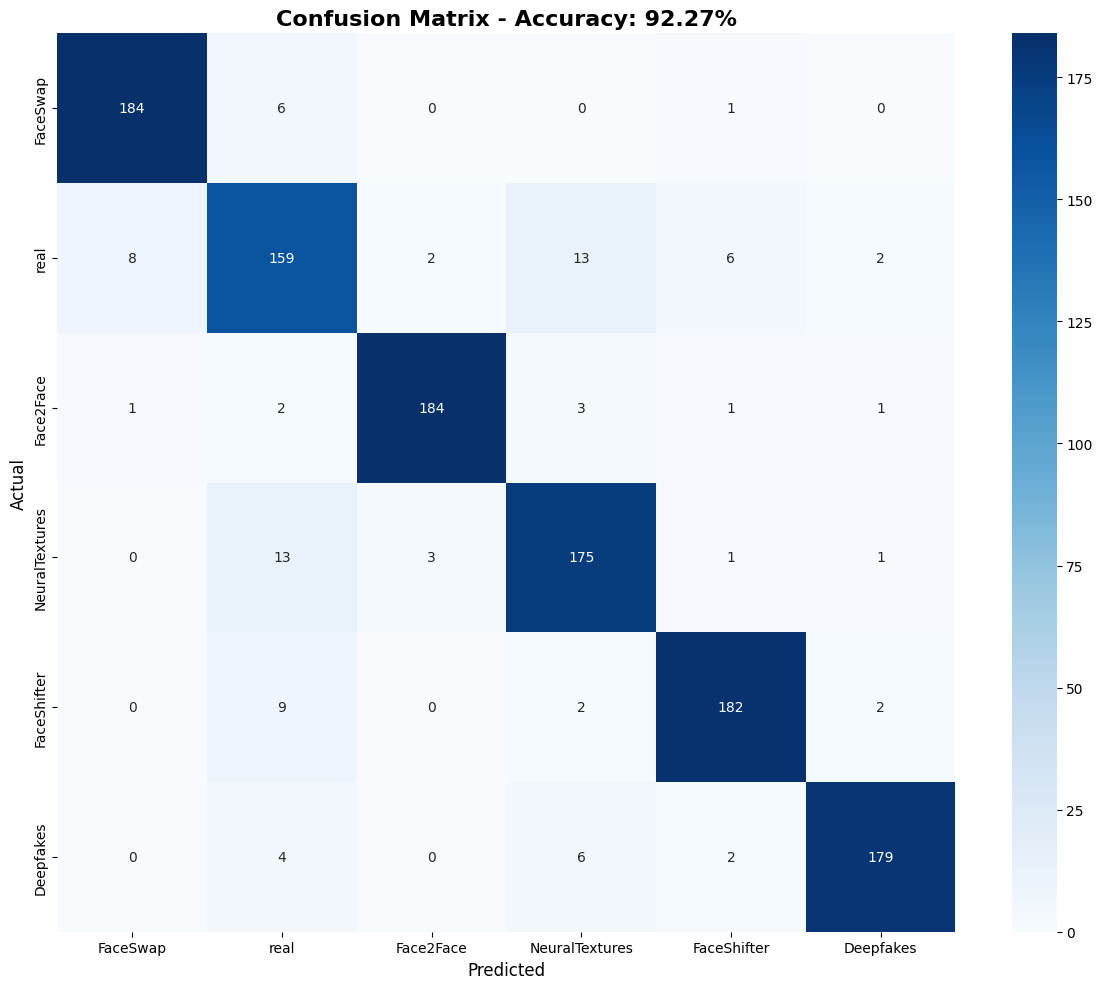


📋 Classification Report:
                precision    recall  f1-score   support

      FaceSwap      0.953     0.963     0.958       191
          real      0.824     0.837     0.830       190
     Face2Face      0.974     0.958     0.966       192
NeuralTextures      0.879     0.907     0.893       193
   FaceShifter      0.943     0.933     0.938       195
     Deepfakes      0.968     0.937     0.952       191

      accuracy                          0.923      1152
     macro avg      0.923     0.923     0.923      1152
  weighted avg      0.924     0.923     0.923      1152


🎯 Per-Class Accuracy:
  FaceSwap       : 96.34%
  real           : 83.68%
  Face2Face      : 95.83%
  NeuralTextures : 90.67%
  FaceShifter    : 93.33%
  Deepfakes      : 93.72%


In [ ]:
print("\n" + "="*80)
print("📊 FINAL EVALUATION")
print("="*80)

# Evaluate
test_loss, test_acc = model.evaluate(test_generator, verbose=1)
print(f"\n🎯 Test Accuracy: {test_acc*100:.2f}%")

# Generate predictions
print("\nGenerating predictions...")
all_preds = []
all_labels = []

for i in tqdm(range(len(test_generator))):
    X_batch, y_batch = test_generator[i]
    preds = model.predict(X_batch, verbose=0)
    all_preds.extend(np.argmax(preds, axis=1))
    all_labels.extend(y_batch)

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['FaceSwap', 'real', 'Face2Face', 'NeuralTextures', 'FaceShifter', 'Deepfakes'],
            yticklabels=['FaceSwap', 'real', 'Face2Face', 'NeuralTextures', 'FaceShifter', 'Deepfakes'])
plt.ylabel('Actual', fontsize=12)
plt.xlabel('Predicted', fontsize=12)
plt.title(f'Confusion Matrix - Accuracy: {test_acc*100:.2f}%', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Classification Report
target_names = ['FaceSwap', 'real', 'Face2Face', 'NeuralTextures', 'FaceShifter', 'Deepfakes']
print("\n📋 Classification Report:")
print(classification_report(all_labels, all_preds, target_names=target_names, digits=3))

# Per-class accuracy
print("\n🎯 Per-Class Accuracy:")
for i, cat in enumerate(target_names):
    class_mask = all_labels == i
    if class_mask.sum() > 0:
        class_acc = (all_preds[class_mask] == i).sum() / class_mask.sum()
        print(f"  {cat:15s}: {class_acc*100:.2f}%")

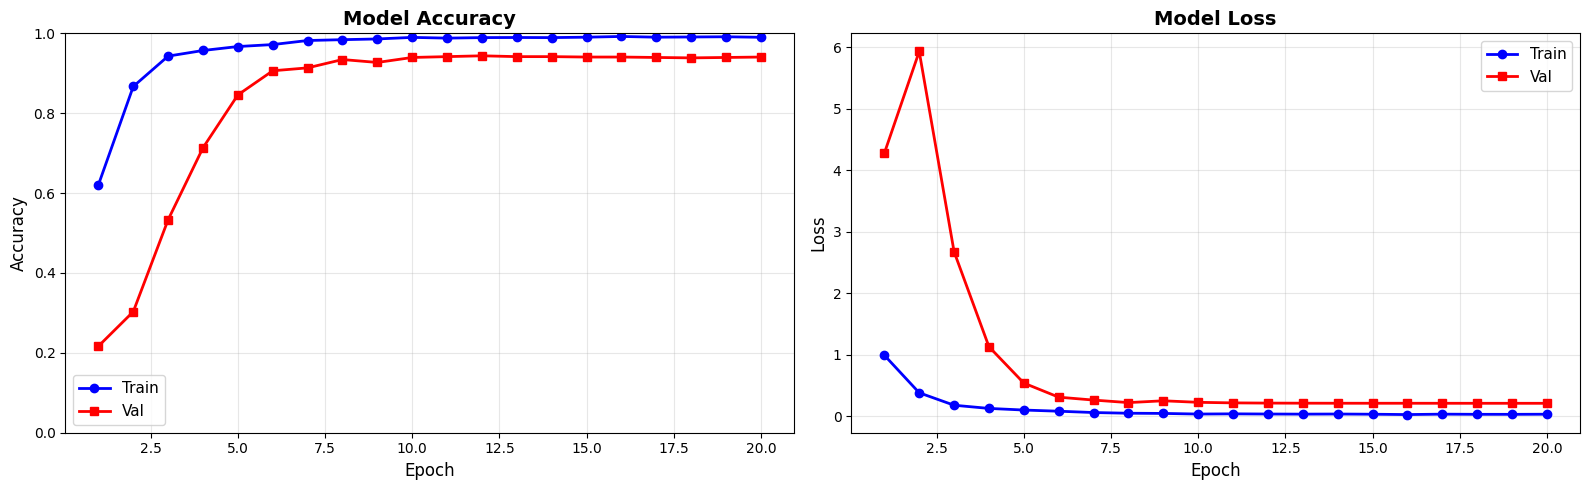


✅ Best validation accuracy: 94.38%
✅ Final test accuracy: 92.27%

📊 SUMMARY:
  Training:   99.01%
  Validation: 94.06%
  Test:       92.27%


In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

epochs_range = range(1, NUM_EPOCHS + 1)

# Accuracy
ax1.plot(epochs_range, history.history['accuracy'], 'b-', label='Train', linewidth=2, marker='o')
ax1.plot(epochs_range, history.history['val_accuracy'], 'r-', label='Val', linewidth=2, marker='s')
ax1.set_title('Model Accuracy', fontsize=14, fontweight='bold')
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Accuracy', fontsize=12)
ax1.legend(fontsize=11)
ax1.grid(True, alpha=0.3)
ax1.set_ylim([0, 1])

# Loss
ax2.plot(epochs_range, history.history['loss'], 'b-', label='Train', linewidth=2, marker='o')
ax2.plot(epochs_range, history.history['val_loss'], 'r-', label='Val', linewidth=2, marker='s')
ax2.set_title('Model Loss', fontsize=14, fontweight='bold')
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Loss', fontsize=12)
ax2.legend(fontsize=11)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\n✅ Best validation accuracy: {best_val_acc*100:.2f}%")
print(f"✅ Final test accuracy: {test_acc*100:.2f}%")

# Summary comparison
print(f"\n📊 SUMMARY:")
print(f"  Training:   {final_train_acc*100:.2f}%")
print(f"  Validation: {final_val_acc*100:.2f}%")
print(f"  Test:       {test_acc*100:.2f}%")

In [ ]:
model.save("deepfake_model.h5")
print("✅ Model saved as deepfake_model.h5")
from google.colab import files
files.download("deepfake_model.h5")


✅ Model saved as deepfake_model.h5


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("="*80)
print("🔧 LOADING TRAINED MODEL FOR INFERENCE")
print("="*80)

import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras

# Load your trained model
MODEL_PATH = 'best_model.keras'  # or from Google Drive

try:
    model = keras.models.load_model(MODEL_PATH)
    print(f"✅ Model loaded from: {MODEL_PATH}")
except:
    # If model is in Google Drive
    from google.colab import drive
    drive.mount('/content/drive')
    MODEL_PATH = '/content/drive/MyDrive/deepfake_detector_balanced_final.keras'
    model = keras.models.load_model(MODEL_PATH)
    print(f"✅ Model loaded from Google Drive")

# Class names
CLASS_NAMES = ['FaceSwap', 'Real', 'Face2Face', 'NeuralTextures', 'FaceShifter', 'Deepfakes']

print(f"\n📊 Model ready for inference!")
print(f"   Classes: {CLASS_NAMES}")

🔧 LOADING TRAINED MODEL FOR INFERENCE
✅ Model loaded from: best_model.keras

📊 Model ready for inference!
   Classes: ['FaceSwap', 'Real', 'Face2Face', 'NeuralTextures', 'FaceShifter', 'Deepfakes']
